# Phishing Website Detection Using Machine Learning

In [1]:
!pip -q install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

phishing = fetch_ucirepo(id=327)
df = pd.concat([phishing.data.features, phishing.data.targets], axis=1)
df.head()

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [3]:
df.shape
df.head()

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [4]:
df.isnull().sum()

,0
having_ip_address,0
url_length,0
shortining_service,0
having_at_symbol,0
double_slash_redirecting,0
prefix_suffix,0
having_sub_domain,0
sslfinal_state,0
domain_registration_length,0
favicon,0


In [5]:
X = phishing.data.features
y = phishing.data.targets.iloc[:, 0]

X.head()

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=2000)
}

In [8]:
scores = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    scores[name] = accuracy_score(y_test, prediction)
    trained_models[name] = model
    print(name)
    print("Accuracy:", scores[name])
    print(classification_report(y_test, prediction))

Decision Tree
Accuracy: 0.9710538218000905
              precision    recall  f1-score   support

          -1       0.97      0.96      0.97       980
           1       0.97      0.98      0.97      1231

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211

Random Forest
Accuracy: 0.9742198100407056
              precision    recall  f1-score   support

          -1       0.98      0.96      0.97       980
           1       0.97      0.98      0.98      1231

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211

Gradient Boosting
Accuracy: 0.952962460425147
              precision    recall  f1-score   support

          -1       0.95      0.94      0.95       980
           1       0.95      0.96      0.96      1231

    accuracy                           0.95      2

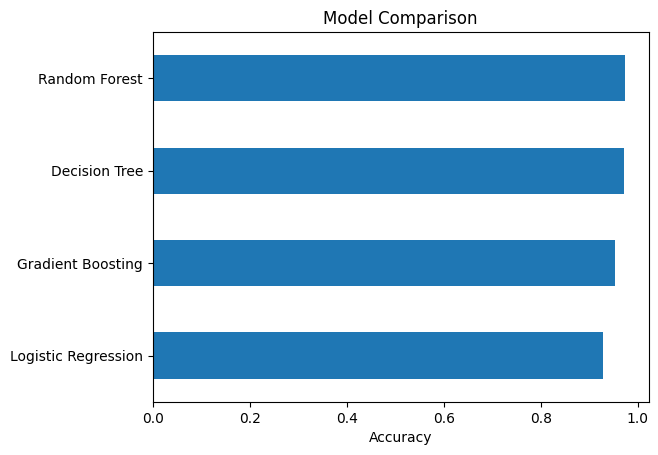

In [9]:
import matplotlib.pyplot as plt

pd.Series(scores).sort_values().plot(kind="barh")
plt.xlabel("Accuracy")
plt.title("Model Comparison")
plt.show()

In [10]:
best_name = max(scores, key=scores.get)
best_model = trained_models[best_name]
print("Best model:", best_name)

Best model: Random Forest


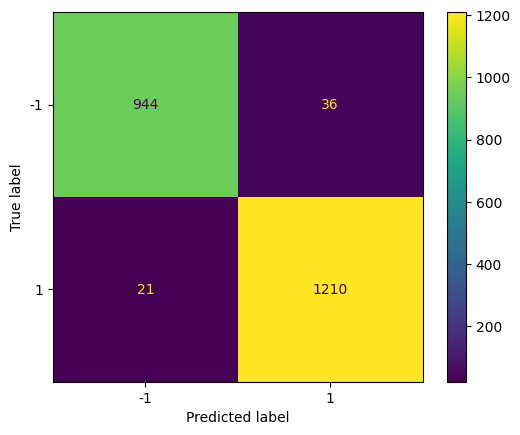

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.show()

In [12]:
import joblib

joblib.dump(best_model, "phishing_detection_model.pkl")
print("Model saved")

Model saved


In [13]:
sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)
print(prediction)

[-1]


This model uses the UCI phishing websites dataset with pre-extracted website features. It is a classroom demonstration and should not be used as the sole basis for real-world security decisions.